# 03 Results and demo

Stratified 5-fold CV sweep over 3 corruption types x 6 levels x {None, PCA, LDA} x {k-NN, GaussianNB}. Imputation, scaling and dimensionality reduction are all fit on the training fold only. `results/results.csv` holds one row per (kind, level, method, clf, fold); regenerate it with `python -m src.experiments.run_sweep` (~1 min).

In [1]:
import os, sys
os.chdir('..'); sys.path.append('.')
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
from src.experiments import plots

df = pd.read_csv('results/results.csv')
print(df.shape, 'rows;', df.fold.nunique(), 'folds')

(540, 11) rows; 5 folds


## 1. Summary tables (mean ± std over 5 folds)

In [2]:
KIND_T = plots.KIND_TITLES
SHOW = [0.0, 0.25, 0.5]
# 0.25 is not in C.LEVELS (steps of 0.1), so the table shows the nearest grid levels 0.2 / 0.3 as well
SHOW = [0.0, 0.2, 0.3, 0.5]

def pivot(col, clf=None, fmt='{:.3f}'):
    d = df[df.level.isin(SHOW)]
    if clf: d = d[d.clf == clf]
    g = d.groupby(['kind', 'method', 'level'])[col].agg(['mean', 'std']).reset_index()
    g['s'] = [fmt.format(m) + ' ± ' + fmt.format(s) for m, s in zip(g['mean'], g['std'])]
    t = g.pivot(index=['kind', 'method'], columns='level', values='s')
    t = t.reindex([(k, m) for k in C.KINDS for m in ['none', 'pca', 'lda']])
    t.columns = [f'{int(l*100)}%' for l in t.columns]
    t.index = pd.MultiIndex.from_tuples([(KIND_T[k], plots.METHOD_NAMES[m]) for k, m in t.index], names=['corruption', 'method'])
    return t

for clf in C.CLASSIFIERS:
    print(f'\n=== Accuracy: {plots.CLF_NAMES[clf]} ==='); display(pivot('acc', clf))
for clf in C.CLASSIFIERS:
    print(f'\n=== Macro-F1: {plots.CLF_NAMES[clf]} ==='); display(pivot('f1', clf))


=== Accuracy: k-NN ===


0%            20%            30%  \
corruption           method                                                
Gaussian Noise       None    0.931 ± 0.004  0.919 ± 0.004  0.906 ± 0.003   
                     PCA     0.926 ± 0.003  0.916 ± 0.004  0.908 ± 0.005   
                     LDA     0.922 ± 0.004  0.884 ± 0.003  0.871 ± 0.011   
Missing Data Dropout None    0.931 ± 0.004  0.853 ± 0.003  0.800 ± 0.010   
                     PCA     0.926 ± 0.003  0.861 ± 0.005  0.812 ± 0.009   
                     LDA     0.922 ± 0.004  0.846 ± 0.007  0.826 ± 0.008   
OOD Rotation+Gain    None    0.931 ± 0.004  0.841 ± 0.007  0.799 ± 0.010   
                     PCA     0.926 ± 0.003  0.837 ± 0.009  0.796 ± 0.006   
                     LDA     0.922 ± 0.004  0.809 ± 0.004  0.773 ± 0.008   

                                       50%  
corruption           method                 
Gaussian Noise       None    0.863 ± 0.005  
                     PCA     0.868 ± 0.006  
                     LDA     0.839 ± 0.003  
Missing Data Dropout None    0.702 ± 0.006  
                     PCA     0.710 ± 0.008  
                     LDA     0.780 ± 0.005  
OOD Rotation+Gain    None    0.729 ± 0.006  
                     PCA     0.724 ± 0.004  
                     LDA     0.699 ± 0.008


=== Accuracy: GaussianNB ===


0%            20%            30%  \
corruption           method                                                
Gaussian Noise       None    0.839 ± 0.006  0.852 ± 0.005  0.849 ± 0.008   
                     PCA     0.860 ± 0.007  0.853 ± 0.009  0.852 ± 0.005   
                     LDA     0.890 ± 0.008  0.878 ± 0.003  0.870 ± 0.006   
Missing Data Dropout None    0.839 ± 0.006  0.831 ± 0.004  0.822 ± 0.006   
                     PCA     0.860 ± 0.007  0.806 ± 0.010  0.783 ± 0.009   
                     LDA     0.890 ± 0.008  0.851 ± 0.009  0.830 ± 0.005   
OOD Rotation+Gain    None    0.839 ± 0.006  0.723 ± 0.009  0.659 ± 0.008   
                     PCA     0.860 ± 0.007  0.739 ± 0.009  0.665 ± 0.016   
                     LDA     0.890 ± 0.008  0.798 ± 0.006  0.765 ± 0.005   

                                       50%  
corruption           method                 
Gaussian Noise       None    0.840 ± 0.008  
                     PCA     0.841 ± 0.008  
                     LDA     0.851 ± 0.006  
Missing Data Dropout None    0.798 ± 0.007  
                     PCA     0.738 ± 0.005  
                     LDA     0.789 ± 0.002  
OOD Rotation+Gain    None    0.586 ± 0.007  
                     PCA     0.613 ± 0.010  
                     LDA     0.700 ± 0.014


=== Macro-F1: k-NN ===


0%            20%            30%  \
corruption           method                                                
Gaussian Noise       None    0.932 ± 0.004  0.919 ± 0.004  0.907 ± 0.003   
                     PCA     0.926 ± 0.003  0.917 ± 0.004  0.909 ± 0.005   
                     LDA     0.922 ± 0.005  0.882 ± 0.003  0.869 ± 0.010   
Missing Data Dropout None    0.932 ± 0.004  0.850 ± 0.003  0.792 ± 0.011   
                     PCA     0.926 ± 0.003  0.859 ± 0.005  0.806 ± 0.009   
                     LDA     0.922 ± 0.005  0.843 ± 0.006  0.822 ± 0.008   
OOD Rotation+Gain    None    0.932 ± 0.004  0.845 ± 0.006  0.804 ± 0.010   
                     PCA     0.926 ± 0.003  0.840 ± 0.009  0.800 ± 0.007   
                     LDA     0.922 ± 0.005  0.812 ± 0.004  0.777 ± 0.007   

                                       50%  
corruption           method                 
Gaussian Noise       None    0.863 ± 0.005  
                     PCA     0.868 ± 0.006  
                     LDA     0.837 ± 0.003  
Missing Data Dropout None    0.684 ± 0.005  
                     PCA     0.694 ± 0.010  
                     LDA     0.776 ± 0.005  
OOD Rotation+Gain    None    0.736 ± 0.006  
                     PCA     0.732 ± 0.004  
                     LDA     0.707 ± 0.008


=== Macro-F1: GaussianNB ===


0%            20%            30%  \
corruption           method                                                
Gaussian Noise       None    0.832 ± 0.006  0.847 ± 0.005  0.844 ± 0.008   
                     PCA     0.856 ± 0.007  0.848 ± 0.009  0.847 ± 0.006   
                     LDA     0.888 ± 0.007  0.876 ± 0.003  0.867 ± 0.007   
Missing Data Dropout None    0.832 ± 0.006  0.824 ± 0.003  0.814 ± 0.006   
                     PCA     0.856 ± 0.007  0.798 ± 0.011  0.773 ± 0.010   
                     LDA     0.888 ± 0.007  0.846 ± 0.009  0.824 ± 0.005   
OOD Rotation+Gain    None    0.832 ± 0.006  0.710 ± 0.015  0.648 ± 0.007   
                     PCA     0.856 ± 0.007  0.733 ± 0.010  0.663 ± 0.018   
                     LDA     0.888 ± 0.007  0.798 ± 0.006  0.766 ± 0.006   

                                       50%  
corruption           method                 
Gaussian Noise       None    0.835 ± 0.009  
                     PCA     0.837 ± 0.008  
                     LDA     0.848 ± 0.007  
Missing Data Dropout None    0.788 ± 0.008  
                     PCA     0.726 ± 0.006  
                     LDA     0.782 ± 0.002  
OOD Rotation+Gain    None    0.567 ± 0.008  
                     PCA     0.609 ± 0.010  
                     LDA     0.701 ± 0.015

In [3]:
print("=== Fisher's criterion tr(S_B)/tr(S_W) on held-out fold (classifier-independent) ===")
display(pivot('fisher', 'knn', '{:.2f}'))
print("=== Retained components (mean ± std over folds) ===")
display(pivot('n_components', 'knn', '{:.1f}'))

=== Fisher's criterion tr(S_B)/tr(S_W) on held-out fold (classifier-independent) ===


0%          20%          30%  \
corruption           method                                           
Gaussian Noise       None     1.03 ± 0.06  0.95 ± 0.05  0.87 ± 0.04   
                     PCA      1.13 ± 0.06  1.05 ± 0.05  0.95 ± 0.05   
                     LDA     17.23 ± 1.28  8.40 ± 0.13  7.15 ± 0.10   
Missing Data Dropout None     1.03 ± 0.06  0.68 ± 0.03  0.55 ± 0.03   
                     PCA      1.13 ± 0.06  0.75 ± 0.04  0.60 ± 0.03   
                     LDA     17.23 ± 1.28  5.15 ± 0.15  4.24 ± 0.15   
OOD Rotation+Gain    None     1.03 ± 0.06  0.68 ± 0.03  0.62 ± 0.03   
                     PCA      1.13 ± 0.06  0.74 ± 0.03  0.67 ± 0.03   
                     LDA     17.23 ± 1.28  6.01 ± 1.19  8.22 ± 0.90   

                                     50%  
corruption           method               
Gaussian Noise       None    0.68 ± 0.03  
                     PCA     0.74 ± 0.03  
                     LDA     5.24 ± 0.10  
Missing Data Dropout None    0.34 ± 0.01  
                     PCA     0.37 ± 0.01  
                     LDA     2.85 ± 0.05  
OOD Rotation+Gain    None    0.53 ± 0.03  
                     PCA     0.57 ± 0.03  
                     LDA     7.93 ± 1.23

=== Retained components (mean ± std over folds) ===


0%         20%         30%         50%
corruption           method                                                
Gaussian Noise       None    63.0 ± 0.0  63.0 ± 0.0  63.0 ± 0.0  63.0 ± 0.0
                     PCA     25.0 ± 0.0  29.0 ± 0.0  35.0 ± 0.0  48.0 ± 0.0
                     LDA      5.0 ± 0.0   5.0 ± 0.0   5.0 ± 0.0   5.0 ± 0.0
Missing Data Dropout None    63.0 ± 0.0  63.0 ± 0.0  63.0 ± 0.0  63.0 ± 0.0
                     PCA     25.0 ± 0.0  47.2 ± 0.4  52.0 ± 0.0  57.0 ± 0.0
                     LDA      5.0 ± 0.0   5.0 ± 0.0   5.0 ± 0.0   5.0 ± 0.0
OOD Rotation+Gain    None    63.0 ± 0.0  63.0 ± 0.0  63.0 ± 0.0  63.0 ± 0.0
                     PCA     25.0 ± 0.0  27.0 ± 0.0  27.0 ± 0.0  28.0 ± 0.0
                     LDA      5.0 ± 0.0   5.0 ± 0.0   5.0 ± 0.0   5.0 ± 0.0

In [4]:
f = df[df.clf == 'knn'].groupby(['kind', 'level', 'method']).fisher.mean().unstack()
f['LDA / PCA'] = f['lda'] / f['pca']
display(f['LDA / PCA'].unstack('level').round(1).rename(index=KIND_T))

level,0.0,0.1,0.2,0.3,0.4,0.5
kind,,,,,,
Gaussian Noise,15.2,8.4,8.0,7.5,7.1,7.0
Missing Data Dropout,15.2,7.2,6.9,7.0,7.3,7.8
OOD Rotation+Gain,15.2,6.2,8.1,12.3,14.2,14.0


## 2. Figures

### Accuracy vs. corruption
Shaded bands are ±1 std over the 5 folds.

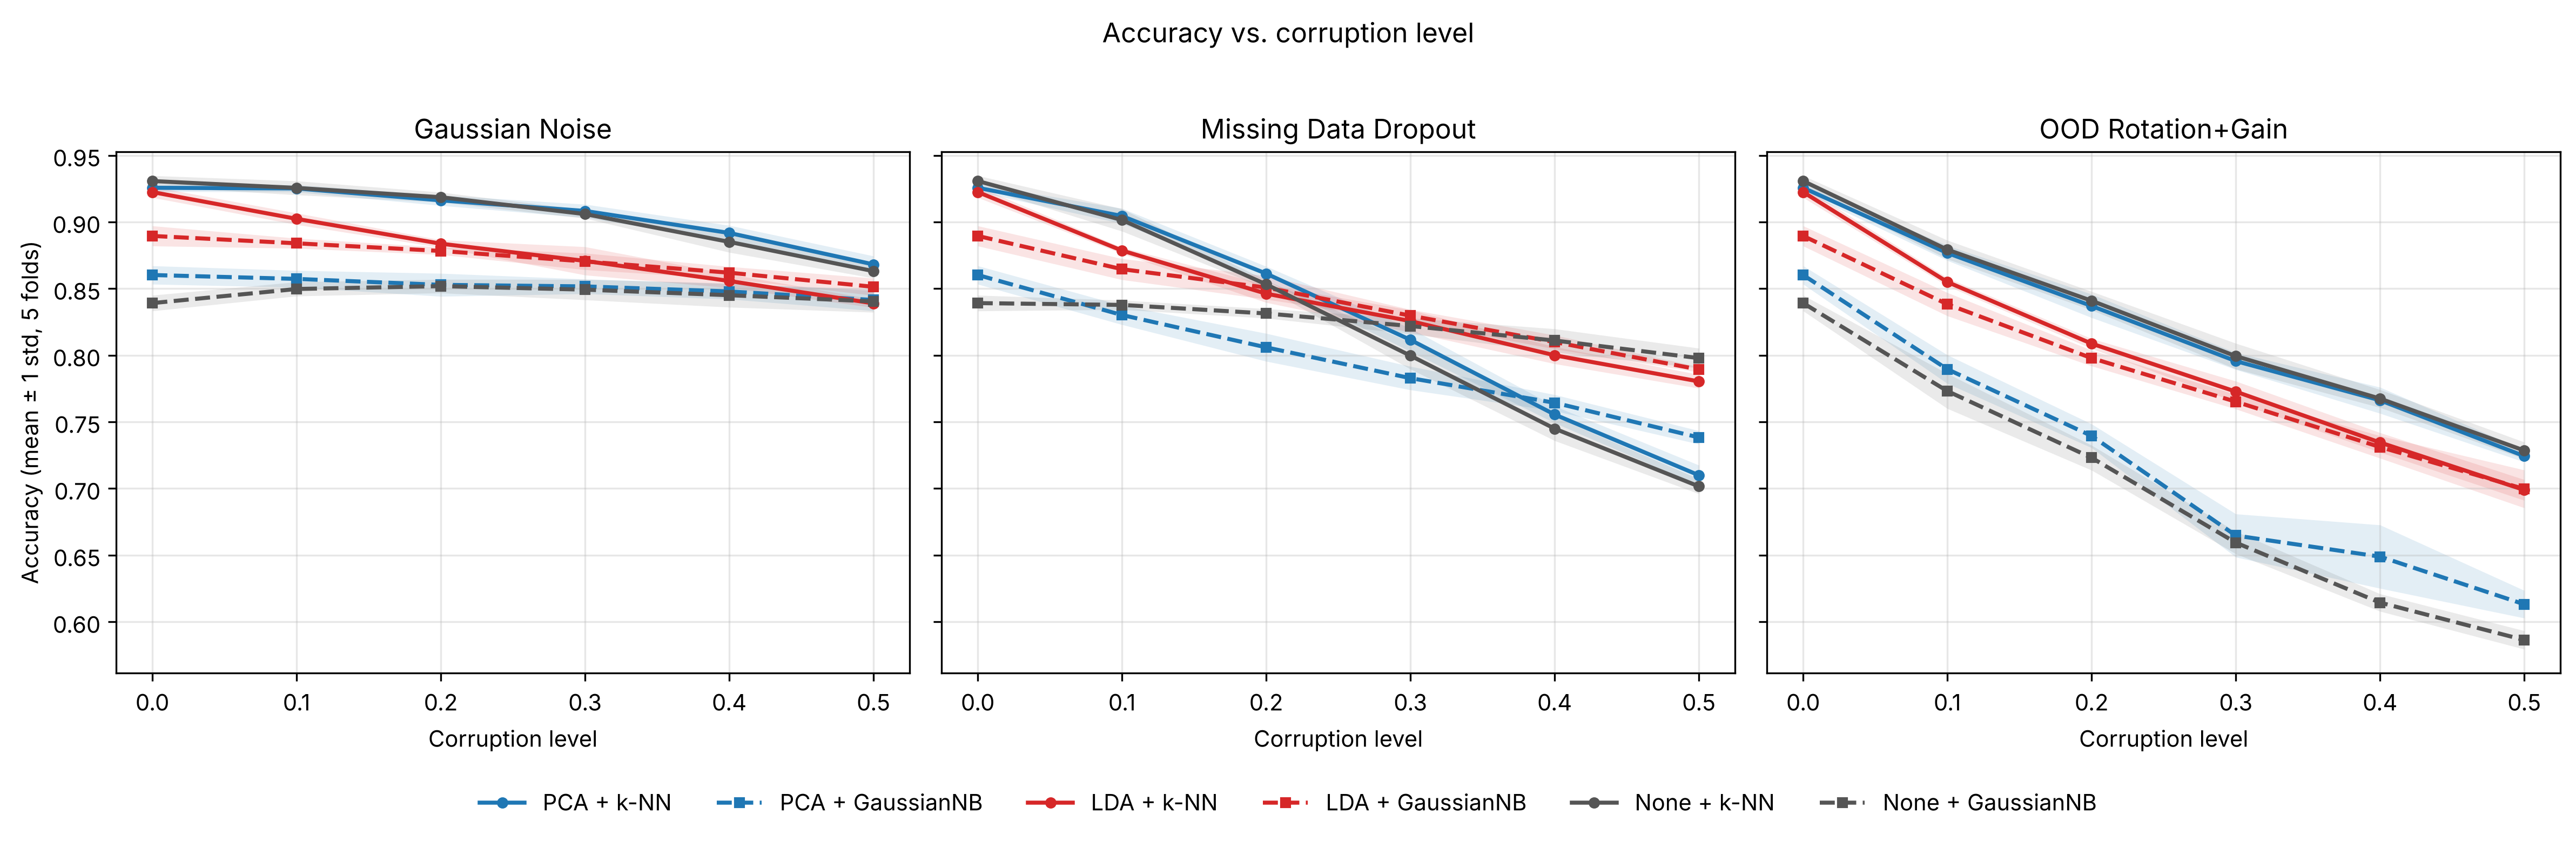

In [5]:
display(Image('results/figures/accuracy_vs_corruption.png'))

### Macro-F1 vs. corruption

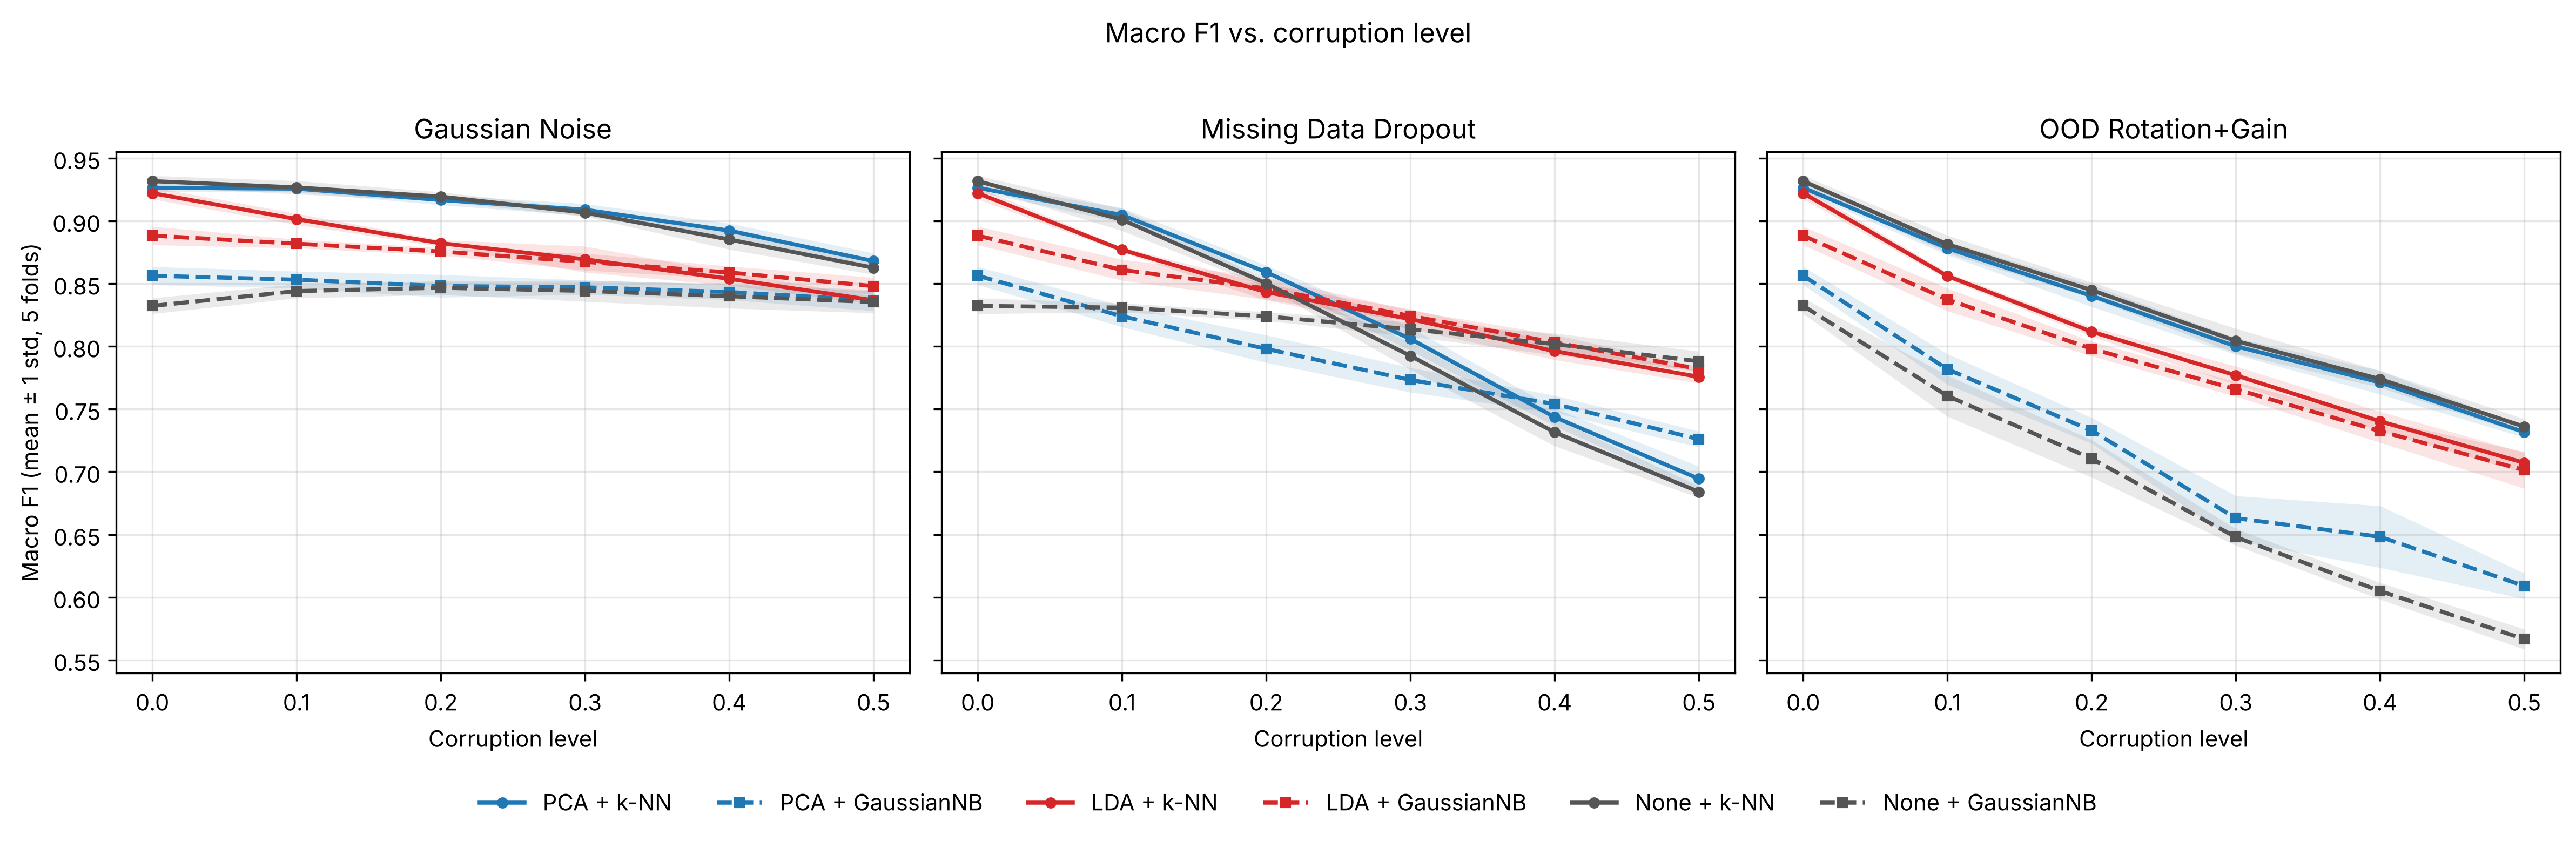

In [6]:
display(Image('results/figures/f1_vs_corruption.png'))

### Fisher's criterion vs. corruption (log scale)

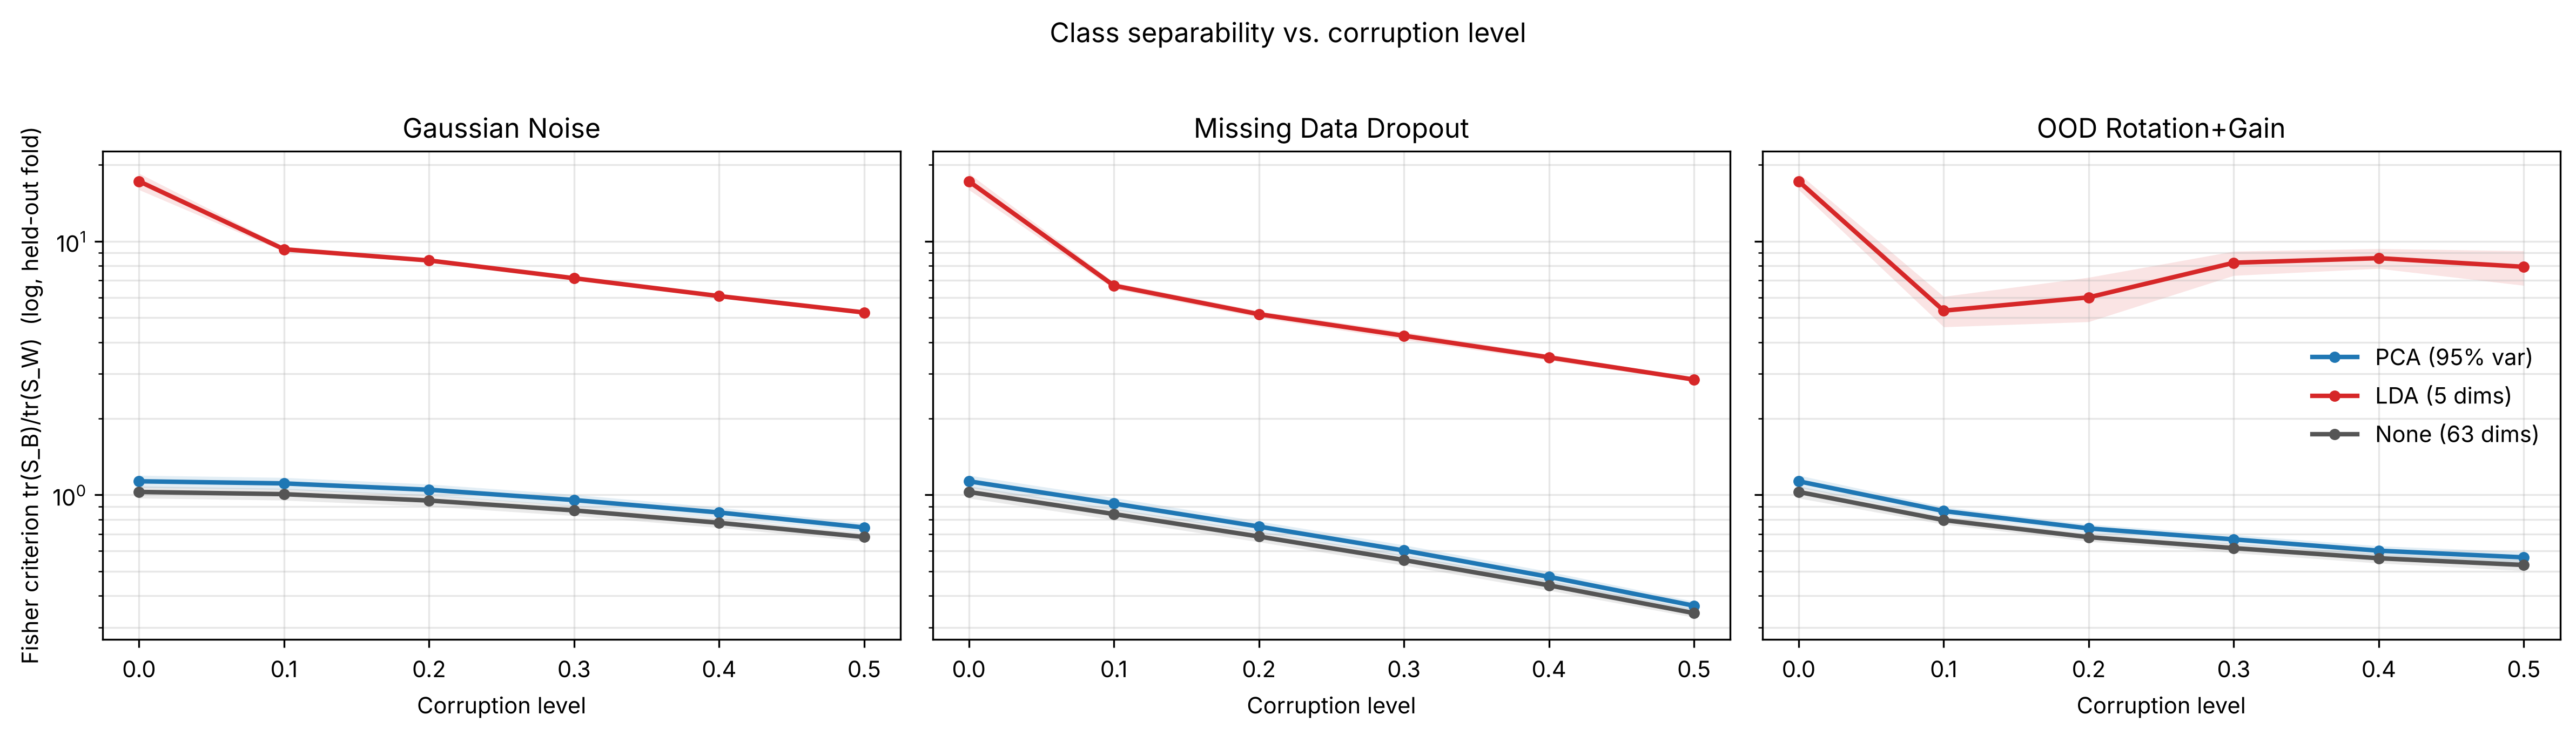

In [7]:
display(Image('results/figures/fisher_vs_corruption.png'))

### Confusion matrices, k-NN, 0% vs. 50% Gaussian noise (row-normalised %)

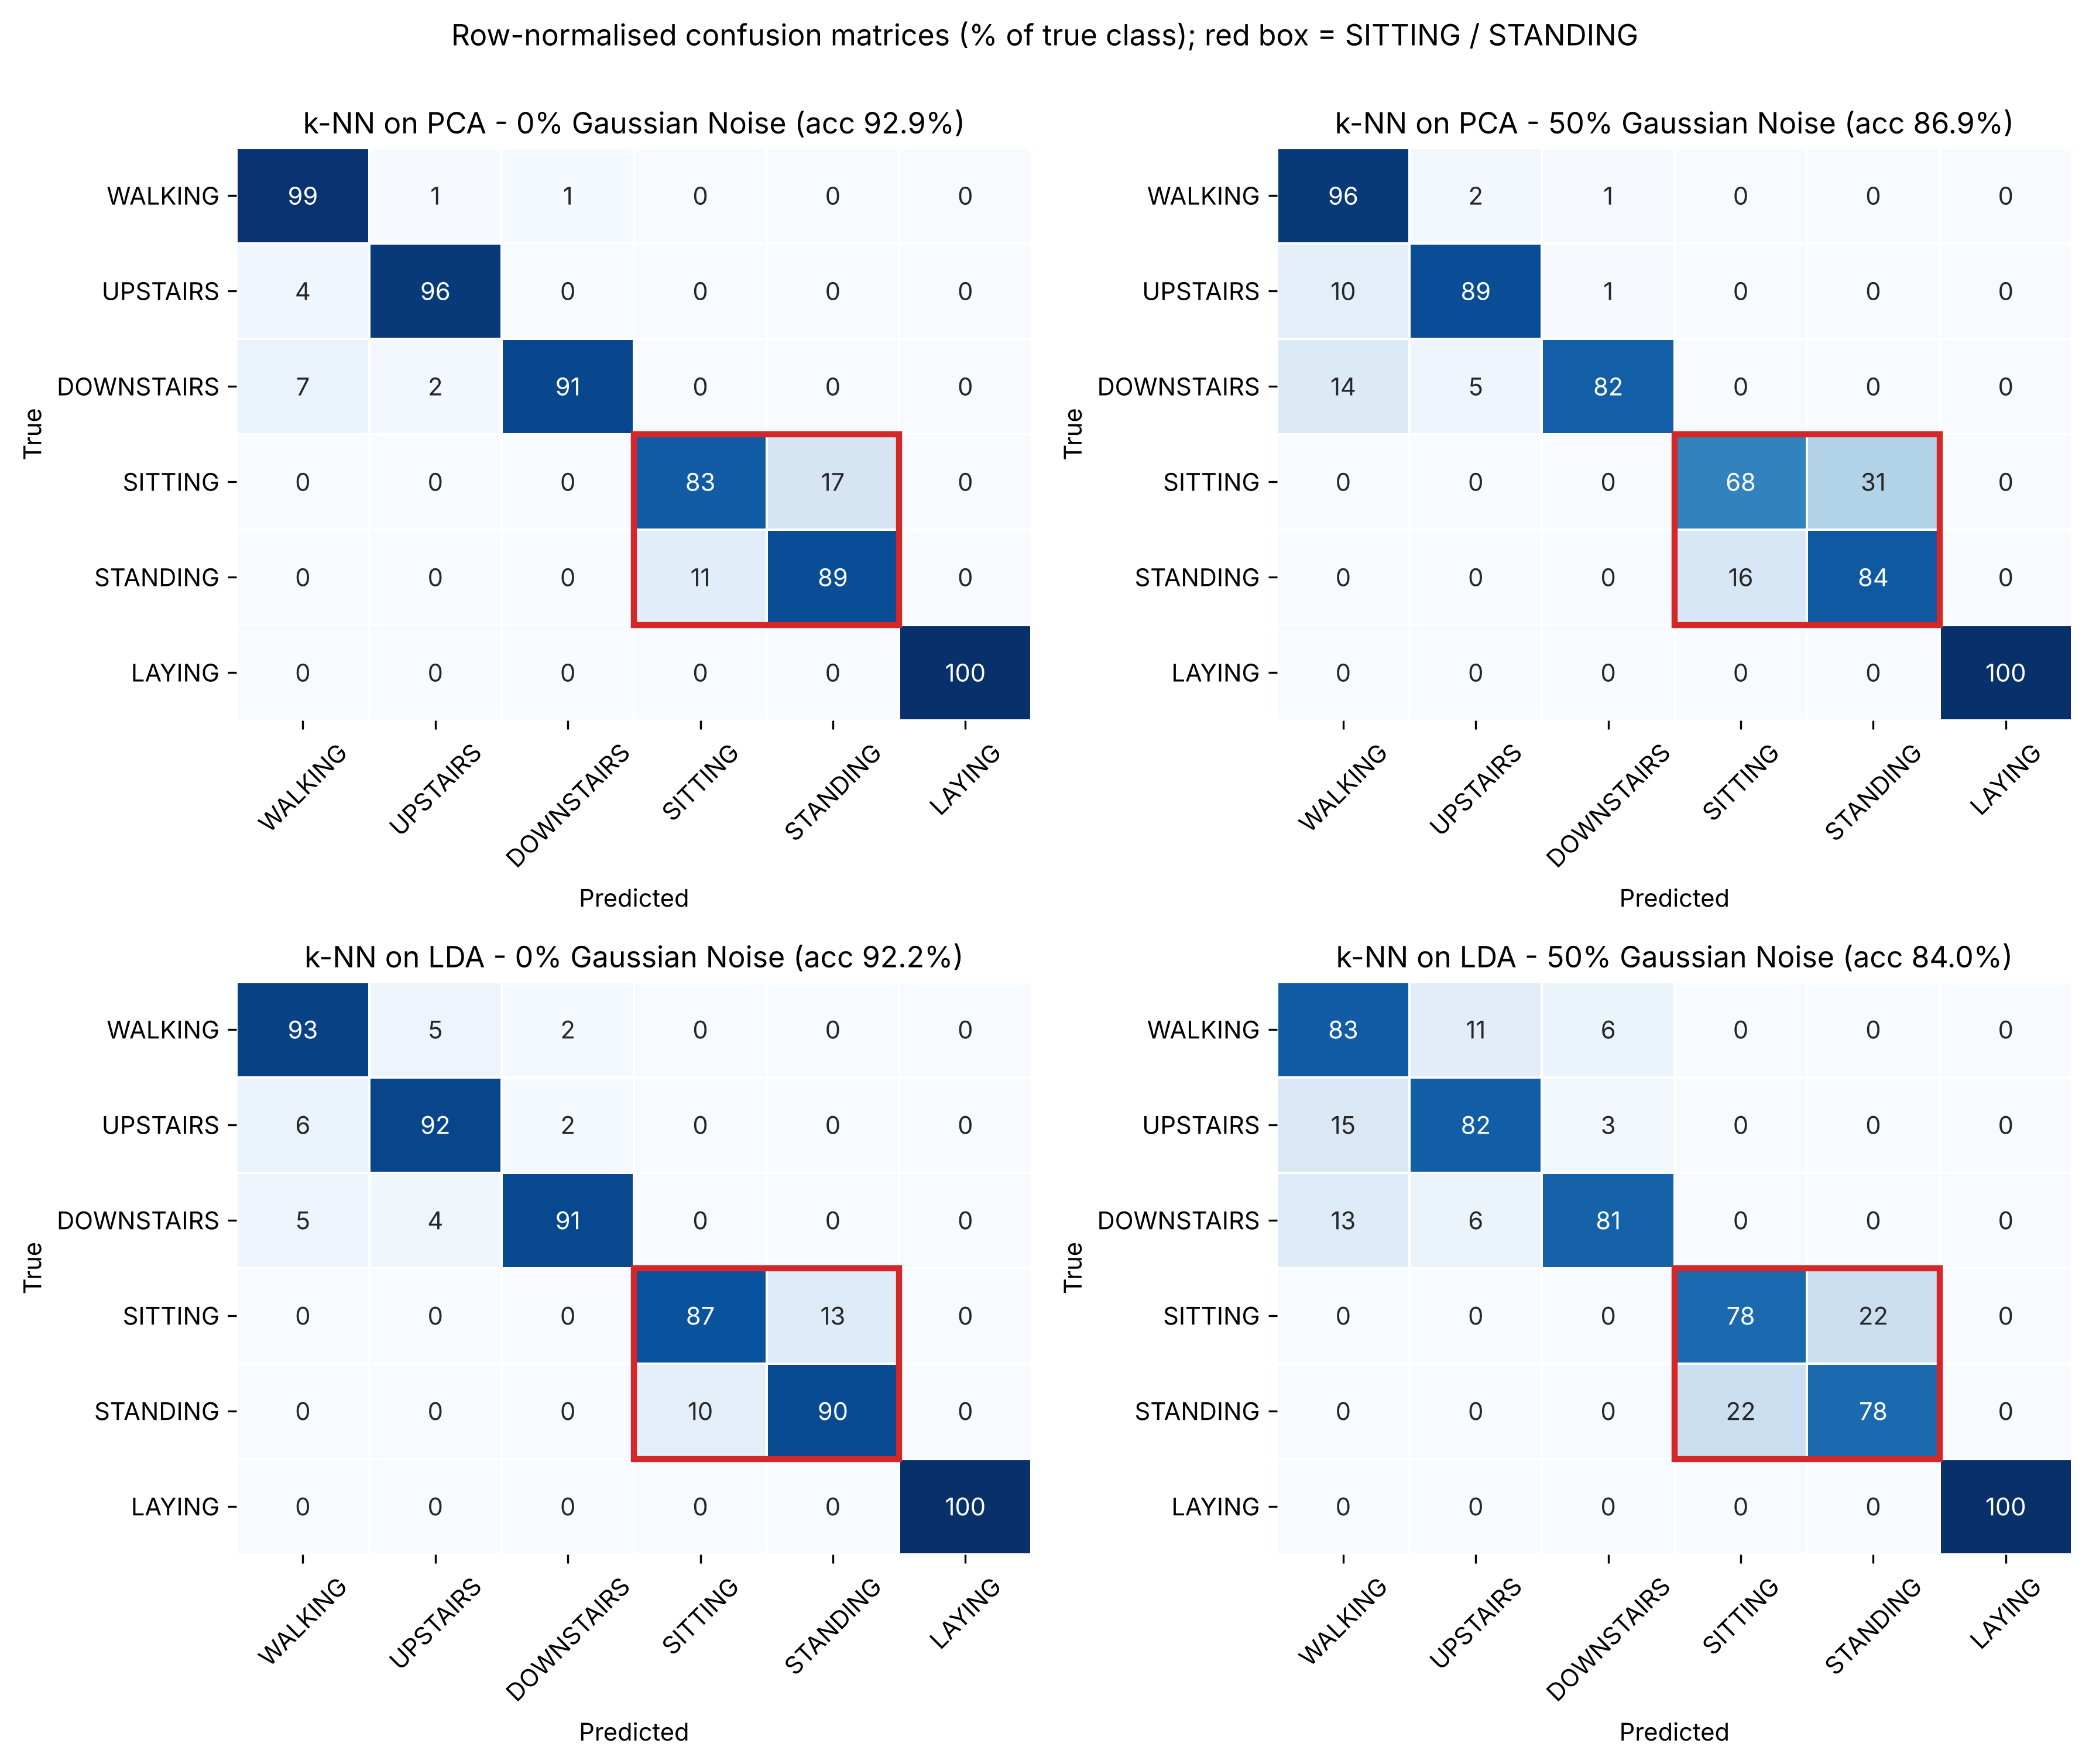

In [8]:
display(Image('results/figures/confusion_matrices_0_vs_50.png'))

### 2-D embeddings under Gaussian noise (0 / 25 / 50%)

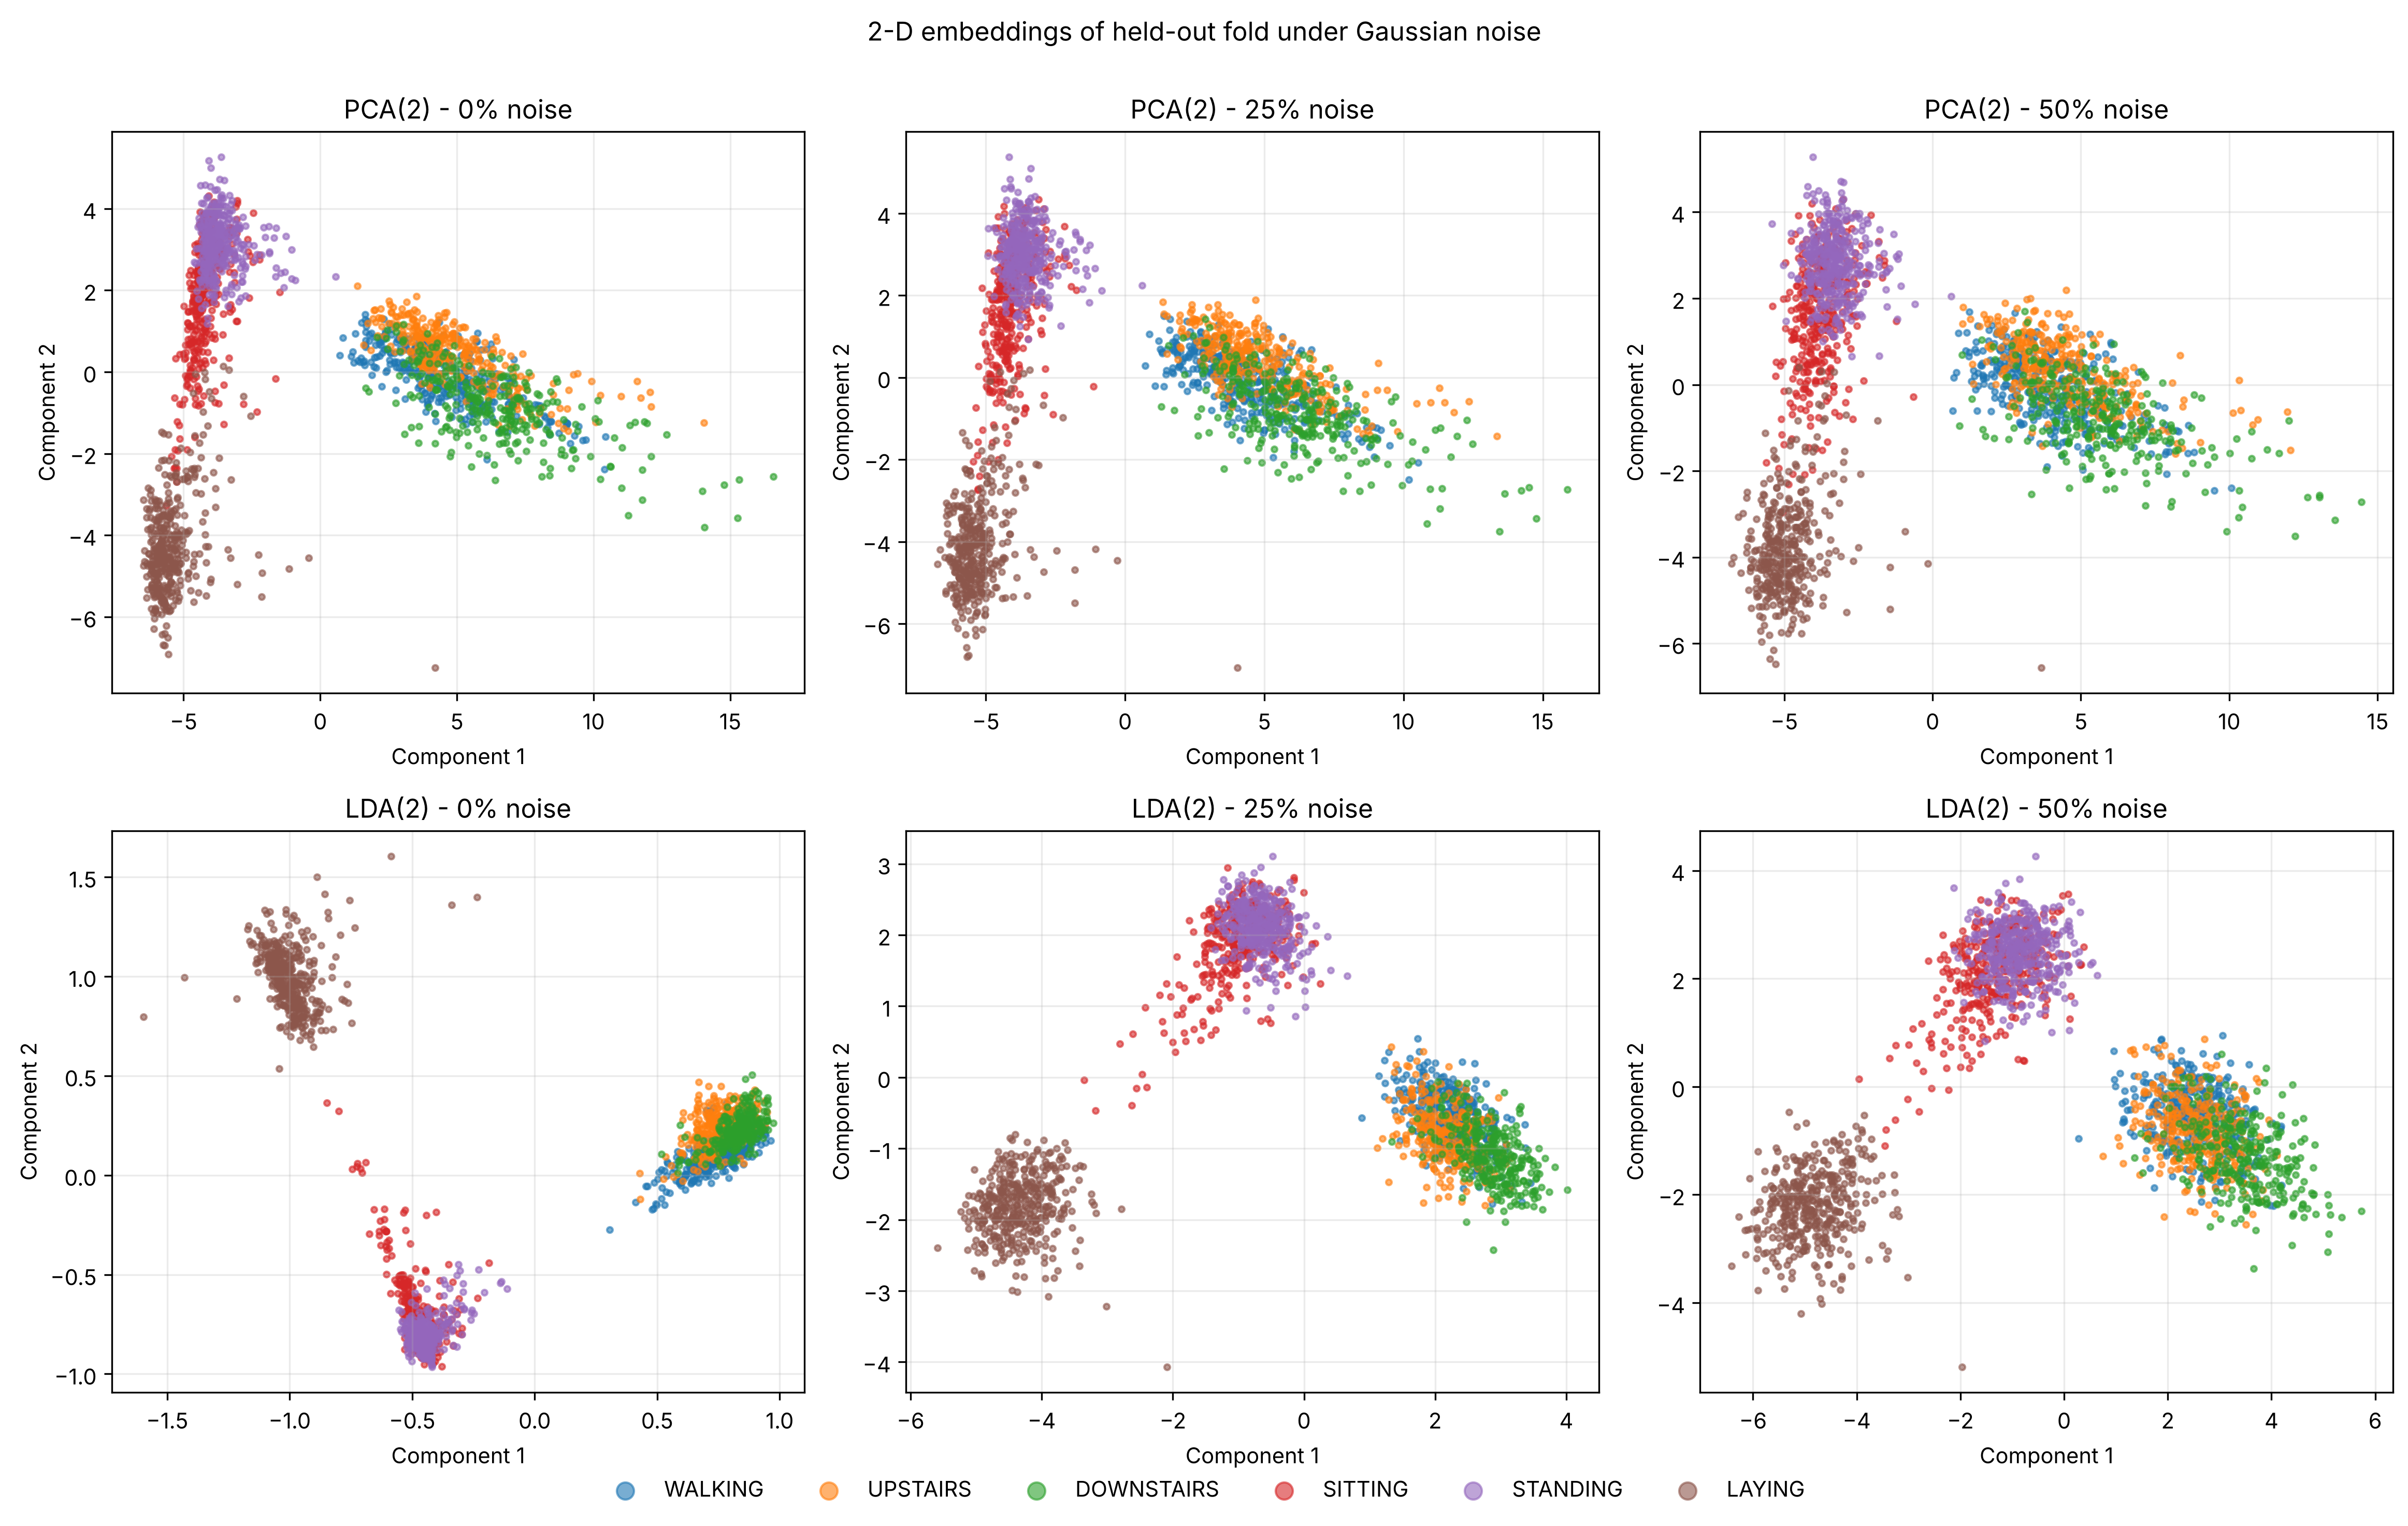

In [9]:
display(Image('results/figures/embeddings_2d_0_25_50.png'))

## 3. Key takeaways (numbers from the tables above)

* **LDA keeps far higher class separability than PCA.** On the held-out fold the Fisher ratio LDA/PCA is ~15x on clean data, and settles at ~7x under Gaussian noise (17.2 -> 5.2 for LDA vs 1.13 -> 0.74 for PCA) and under missing data (~7-8x). Under OOD rotation+gain the gap actually *widens* (~12-14x at 30-50%): LDA's learned directions are mostly insensitive to the rotation/gain, whereas PCA's variance-driven directions are not. PCA and the raw 63-d space have almost identical, low (~1) Fisher scores: maximising variance does not maximise class separation.
* **PCA's retained-component count grows with noise.** To keep 95% of the variance, PCA needs 25 components clean but ~48 at 50% Gaussian noise and ~57 at 50% missing data (nearly all 63): isotropic noise / mean-imputed gaps add variance in every direction, flattening the eigenvalue spectrum, so "95% variance" increasingly means "keep the noise". Under OOD it stays ~27-28 because the transform is a structured, low-dimensional change.
* **k-NN vs. GaussianNB.** On clean data k-NN is clearly better on PCA/raw features (~93% vs ~84-86%) because GaussianNB's independence assumption is violated by correlated features; on LDA (5 decorrelated, class-whitened dims) the gap shrinks (92% vs 89%). GaussianNB degrades more slowly under Gaussian/missing corruption (it is already a smooth, low-variance model) and overtakes k-NN at high missing-data levels, but is much worse under OOD shift (e.g. ~59-61% vs ~72-73% for None/PCA at 50%) since a class-conditional Gaussian with tiny variances is very sensitive to mean shifts.
* **Higher Fisher does not automatically mean higher accuracy.** At 50% Gaussian noise LDA has ~7x the Fisher score of PCA, yet k-NN on LDA is slightly *below* k-NN on PCA/None (~84% vs ~87%): LDA is a supervised projection fit on a noisy training fold and has only 5 dims, so noisy training points overlap in the embedding, and any train/test mismatch is not corrected by the Fisher metric (which is computed on the test fold only).
* **Hard pair: SITTING vs. STANDING.** Dynamic activities (WALKING/UP/DOWN) form one cluster and LAYING is always perfect, so nearly all errors are SITTING<->STANDING (and within the walking family). Noise increases SITTING->STANDING confusion from 17% to 31% under PCA, vs 13% to 22% under LDA - LDA degrades more evenly, but the two classes overlap heavily in both embeddings.

## 4. Live demo
Change `DEMO_KIND` (`gaussian` | `missing` | `ood`) and `DEMO_LEVEL` (0.0-0.5) and re-run. Uses a single stratified 80/20 split, so it takes about a second.

In [10]:
import time
from sklearn.model_selection import train_test_split
from src.data.load import load_raw
from src.data.features import extract_features
from src.data.corrupt import corrupt, mean_impute
from src.reduction.scaler import StandardScaler
from src.reduction.pca import PCA
from src.reduction.lda import LDA
from src.reduction.fisher import fisher_score
from src.models.knn import KNN
from src.models.gnb import GaussianNB

DEMO_KIND = "gaussian"   # "gaussian" | "missing" | "ood"
DEMO_LEVEL = 0.3         # 0.0 .. 0.5

_X_raw, _y, _ = load_raw(C.DATA_DIR)      # cached for fast re-runs
_X = extract_features(_X_raw)

def demo(kind=DEMO_KIND, level=DEMO_LEVEL):
    t0 = time.time()
    Xc = corrupt(_X, _X_raw, kind=kind, level=level, seed=C.SEED)
    tr, te = train_test_split(np.arange(len(_y)), test_size=0.2, stratify=_y, random_state=C.SEED)
    Xtr, Xte = mean_impute(Xc[tr], Xc[te])
    sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    ytr, yte = _y[tr], _y[te]
    rows = []
    for name, red in [('None (63 dims)', None), ('PCA (95% var)', PCA(C.PCA_VAR).fit(Xtr)), ('LDA (5 dims)', LDA(C.LDA_DIMS).fit(Xtr, ytr))]:
        Ztr, Zte = (Xtr, Xte) if red is None else (red.transform(Xtr), red.transform(Xte))
        rows.append({'method': name, 'dims': Ztr.shape[1], 'Fisher': round(fisher_score(Zte, yte), 3),
                     'k-NN acc': round((KNN(C.KNN_K).fit(Ztr, ytr).predict(Zte) == yte).mean(), 3),
                     'GNB acc': round((GaussianNB().fit(Ztr, ytr).predict(Zte) == yte).mean(), 3)})
    print(f'{KIND_T[kind]} @ {level:.0%}  (done in {time.time()-t0:.1f}s)')
    return pd.DataFrame(rows).set_index('method')

demo()

Gaussian Noise @ 30%  (done in 0.5s)


,dims,Fisher,k-NN acc,GNB acc
method,,,,
None (63 dims),63,0.859,0.900,0.852
PCA (95% var),35,0.942,0.902,0.844
LDA (5 dims),5,7.196,0.860,0.868
